# Lab | EDA Univariate Analysis

## Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## Load Data

In [2]:
df = pd.read_csv("data/amz_uk_price_prediction_dataset.csv")

## Initial Exploration

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


In [5]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [6]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

## Part 1 | Product Categories


**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

In [7]:
category_frequency = df["category"].value_counts()

category_frequency

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

### Insights

* The dataset contains **296 unique product categories**.
* **Sports & Outdoors** is the most frequently listed category with **836,265 products**.
* **Beauty** is the second most frequent category with **19,312 products**.
* There is a substantial difference between Sports & Outdoors and the remaining categories, indicating a highly uneven category distribution.

In [11]:
top5_categories = df["category"].value_counts().head(5)

top5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

### Top Five Categories

The five most frequently listed product categories are:

1. Sports & Outdoors
2. Beauty
3. Handmade Clothing, Shoes & Accessories
4. Bath & Body
5. Birthday Gifts

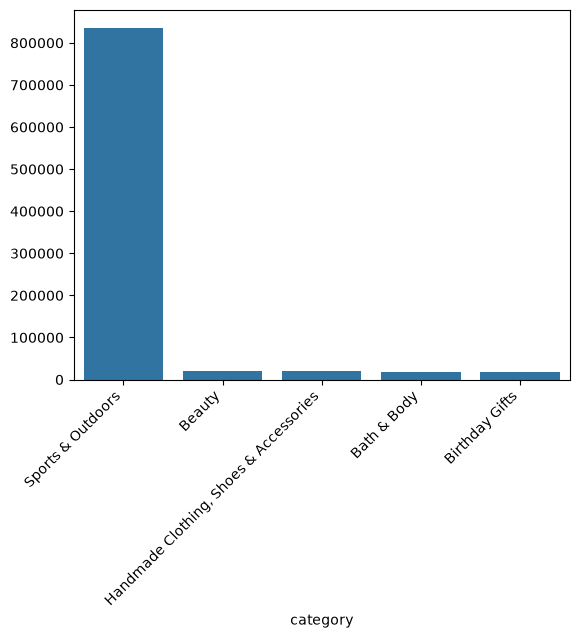

In [14]:
sns.barplot(
    x=top5_categories.index,
    y=top5_categories.values)

plt.xticks(rotation=45, ha="right")
plt.show()

### Insights from the Bar Chart

The dataset contains 296 product categories. Plotting all categories in one bar chart would make the category names and differences difficult to read. Therefore, the visualization focuses on the five most frequently listed categories.

1. **Sports & Outdoors** has a considerably higher listing frequency than the other four categories.
2. The remaining top categories have relatively similar listing frequencies.
3. The large difference between the first and second categories confirms that the category distribution is highly uneven.


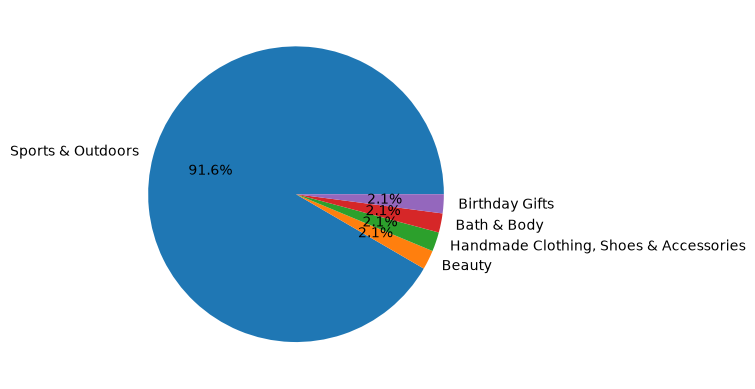

In [17]:
top5_categories.plot.pie(
    autopct="%1.1f%%"
)

plt.show()

### Insights from the Pie Chart

* **Sports & Outdoors** represents approximately **91.6%** of the listings within the top five categories.
* Each of the remaining categories accounts for approximately **2.1%**.
* The pie chart confirms that Sports & Outdoors clearly dominates the top-five product listings.
* The dominance of one category makes it difficult to distinguish the differences between the smaller categories.

### Business Question Conclusion

The Amazon UK dataset contains a large number of product categories, but the distribution of listings is highly uneven. Sports & Outdoors dominates the dataset, while the remaining categories contain considerably fewer products.

## Part 2 | Product Pricing


**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

In [18]:
mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()

print("Mean:", mean_price)
print("Median:", median_price)
print("Mode:")
print(mode_price)

Mean: 89.24380943923661
Median: 19.09
Mode:
0    9.99
Name: price, dtype: float64


### Insights

* The average product price is **£89.24**.
* The median product price is **£19.09**, meaning half of the products are priced below this value.
* The most common product price is **£9.99**.
* The mean is considerably higher than both the median and the mode, suggesting that a small number of high-priced products increase the average price.

In [19]:
variance_price = df["price"].var()
std_price = df["price"].std()
range_price = df["price"].max() - df["price"].min()
iqr_price = df["price"].quantile(0.75) - df["price"].quantile(0.25)

print("Variance:", variance_price)
print("Standard Deviation:", std_price)
print("Range:", range_price)
print("Interquartile Range:", iqr_price)

Variance: 119445.48532254901
Standard Deviation: 345.60886175349873
Range: 100000.0
Interquartile Range: 36.0


### Insights

* The standard deviation of **345.61** indicates that product prices vary considerably.
* The price range is **£100,000**, showing a very large difference between the least and most expensive products.
* The interquartile range (IQR) is **£36.00**, meaning the middle 50% of product prices are spread over a relatively small range.
* The much larger range and standard deviation compared to the IQR suggest that a small number of very expensive products are increasing the overall variability.

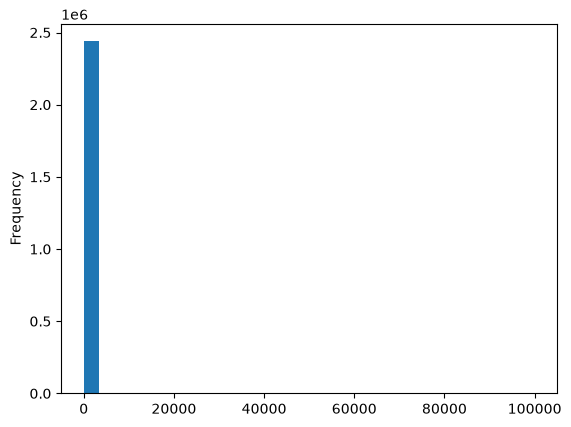

In [20]:
df["price"].plot(kind="hist", bins=30)

plt.show()

### Insights

* Most product prices are concentrated at the lower end of the price range.
* A small number of very expensive products stretch the distribution.
* The histogram is difficult to interpret because the extreme values compress most observations into the first few bins.

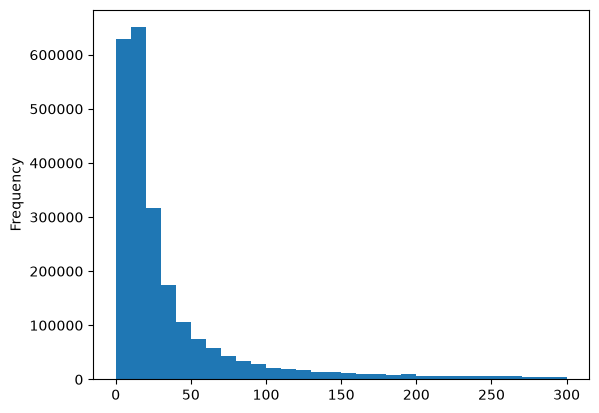

In [21]:
df[df["price"] <= 300]["price"].plot(kind="hist", bins=30)

plt.show()

### Insights

* Most products are priced below **£50**.
* The frequency of products decreases as the price increases.
* The distribution is **right-skewed**, with a long tail extending toward higher prices.
* Relatively few products are priced above **£100** compared to the large number of lower-priced products.

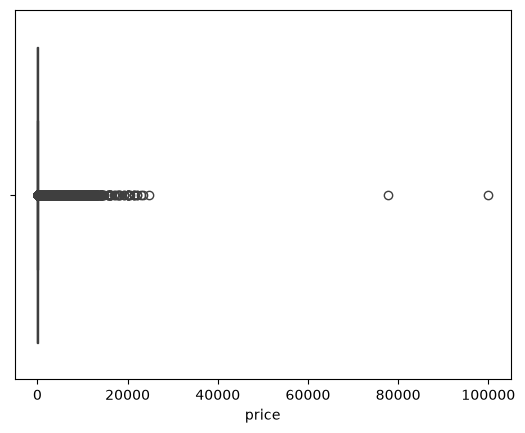

In [22]:
sns.boxplot(x=df["price"])

plt.show()

### Insights

* Most products are concentrated within a relatively low price range.
* The box plot shows a large number of high-price outliers.
* Two extreme outliers, priced around **£80,000** and **£100,000**, are clearly separated from the rest of the data.
* The large number of outliers confirms that the price distribution is highly right-skewed.

### Business Question Conclusion

Most Amazon UK products are relatively inexpensive, with prices concentrated at the lower end of the distribution. A small number of premium-priced products create substantial variation and numerous high-price outliers.

## Part 3 | Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

In [24]:
mean_stars = df["stars"].mean()
median_stars = df["stars"].median()
mode_stars = df["stars"].mode()

print("Mean:", mean_stars)
print("Median:", median_stars)
print("Mode:")
print(mode_stars)

Mean: 2.152836472966066
Median: 0.0
Mode:
0    0.0
Name: stars, dtype: float64


### Insights

* The average product rating is **2.15 stars**.
* The median rating is **0.0 stars**, meaning at least half of the products have a rating of 0.
* The most common rating is **0.0 stars**.
* The difference between the mean and the median suggests that many products have no ratings, while a smaller number of highly rated products increase the average.

In [25]:
variance_stars = df["stars"].var()
std_stars = df["stars"].std()
iqr_stars = df["stars"].quantile(0.75) - df["stars"].quantile(0.25)

print("Variance:", variance_stars)
print("Standard Deviation:", std_stars)
print("Interquartile Range:", iqr_stars)

Variance: 4.817434029796864
Standard Deviation: 2.194865378513421
Interquartile Range: 4.4


### Insights

* The standard deviation of **2.19 stars** indicates that product ratings vary considerably across the dataset.
* The variance of **4.82** confirms that there is noticeable variability in product ratings.
* The interquartile range (IQR) is **4.4 stars**, showing that the middle 50% of ratings span a wide range.
* The large IQR, together with the median of **0.0**, suggests that while many products have no ratings, others receive ratings across almost the entire 0–5 star scale.

In [26]:
skewness = df["stars"].skew()
kurtosis = df["stars"].kurt()

print("Skewness:", skewness)
print("Kurtosis:", kurtosis)

Skewness: 0.08120735761080881
Kurtosis: -1.9260061280432994


### Insights

* The skewness is **0.08**, indicating that the distribution of product ratings is approximately symmetric with a slight positive skew.
* The kurtosis is **-1.93**, suggesting a flatter distribution than a normal distribution.
* Overall, the ratings are spread across the rating scale rather than being highly concentrated around a single value.

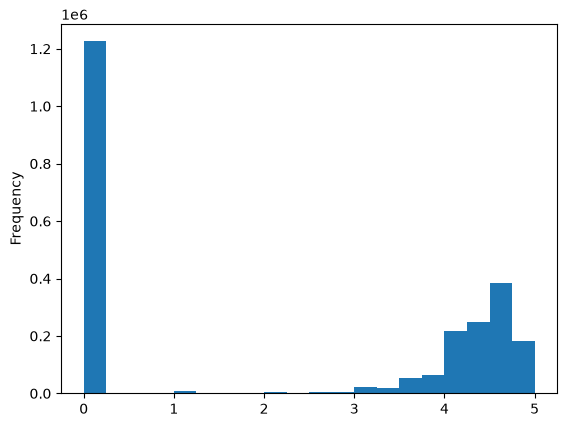

In [ ]:
df["stars"].plot(kind="hist", bins=20)

plt.show()

### Insights

* A large number of products have **0-star ratings**, indicating that many products have not yet received customer ratings.
* Among the products that have ratings, most are concentrated between **4 and 5 stars**.
* There are relatively few products with ratings between **1 and 3 stars**.
* The histogram shows two clear concentrations: one at **0 stars** and another around **4–5 stars**.

### Business Question Conclusion

Many products in the dataset have not yet received customer ratings. Among the products that have been rated, most receive high ratings between 4 and 5 stars, indicating generally positive customer feedback.

## Conclusions

This exploratory data analysis examined Amazon UK products by analyzing product categories, prices, and customer ratings.

Key findings include:

- The dataset contains **296 product categories**, with **Sports & Outdoors** representing the largest category by a substantial margin.
- Product prices are highly right-skewed, with most products priced at the lower end and a small number of premium-priced products creating many outliers.
- Many products have not yet received customer ratings.
- Among the products that have ratings, most are rated between **4 and 5 stars**, indicating generally positive customer feedback.

Overall, the dataset demonstrates considerable variation across categories, prices, and customer ratings, providing a solid foundation for further exploratory and predictive analyses.